# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Arshad Ali Khokhar
- **Student ID:** 023-24-0029
- **Section:** B
- **GitHub:** https://github.com/arshadalikhokhar05-sketch/machine-learning-data-preprocessing-lab
- **Kaggle:** https://www.kaggle.com/reformist
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn
---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
df = pd.read_csv("telco_churn.csv")

# Replace cells that are entirely whitespace with NaN values
df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

clean_df = df.copy()

redundant_cats = {'No phone service': 'No', 'No internet service': 'No'}
clean_df.replace(redundant_cats, inplace=True)
clean_df.drop(columns=['customerID'], inplace=True)

# Force TotalCharges to be numeric (turns blank spaces into NaN)
clean_df['TotalCharges'] = pd.to_numeric(clean_df['TotalCharges'], errors='coerce')

# Drop the 11 rows with the newly created NaN values
clean_df.dropna(subset=['TotalCharges'], inplace=True)

In [ ]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)

# encoding
y = clean_df['Churn'].map({"Yes": 1, "No": 0})
X = clean_df.drop(columns=['Churn'])

binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
  X[col] = X[col].map({"Yes" : 1, "No" : 0})

# transforming gender column separately since it doesnt have yes no
X['gender'] = X['gender'].map({'Female' : 1, 'Male' : 0})

# Transform other categorical columns
cols = X.select_dtypes(include=['object']).columns.tolist()
X = pd.get_dummies(X, columns=cols, drop_first=True ,dtype=int)

print(f"X shape: {X.shape}")
print(f"Y shape: {y.shape}" )
print(f"Non numeric columns: {len(X.select_dtypes(exclude=["number"]).columns)}")
print(f"Missing values count: {X.isnull().sum().sum()}")
print(f"Target distribution in y: {y.value_counts(normalize=True)}")

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

X shape: (7032, 23)
Y shape: (7032,)
Non numeric columns: 0
Missing values count: 0
Target distribution in y: Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64


C:\Users\User\AppData\Local\Temp\ipykernel_12020\1050329103.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols = X.select_dtypes(include=['object']).columns.tolist()


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [ ]:
import warnings
import time
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
# unscaled linear SVM

svm_raw = SVC(kernel='linear', random_state=42)

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    start_time = time.time()
    svm_raw.fit(X_train, y_train)
    unscaled_train_time = time.time() - start_time

unscaled_warned = any(issubclass(w.category, ConvergenceWarning) for w in caught_warnings)
unscaled_warning_status = "Yes (Failed to converge)" if unscaled_warned else "None"

y_pred_unscaled = svm_raw.predict(X_test)
acc_unscaled = accuracy_score(y_test, y_pred_unscaled)
f1_unscaled = f1_score(y_test, y_pred_unscaled)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
# scaled linear SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_scaled = SVC(kernel='linear', random_state=42)

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    start_time = time.time()
    svm_scaled.fit(X_train_scaled, y_train)
    scaled_train_time = time.time() - start_time

scaled_warned = any(issubclass(w.category, ConvergenceWarning) for w in caught_warnings)
scaled_warning_status = "Yes (Failed to converge)" if scaled_warned else "None"

y_pred_scaled = svm_scaled.predict(X_test_scaled)
acc_scaled = accuracy_score(y_test, y_pred_scaled)
f1_scaled = f1_score(y_test, y_pred_scaled)

results = pd.DataFrame({
    'Metric': ['Training Time (s)', 'Accuracy', 'F1-Score', 'Convergence Warning'],
    'Unscaled SVM': [f"{unscaled_train_time:.3f} s", f"{acc_unscaled:.4f}", f"{f1_unscaled:.4f}", unscaled_warning_status],
    'Scaled SVM': [f"{scaled_train_time:.3f} s", f"{acc_scaled:.4f}", f"{f1_scaled:.4f}", scaled_warning_status]
})

print(results.to_string(index=False))

             Metric Unscaled SVM Scaled SVM
  Training Time (s)    396.041 s    1.693 s
           Accuracy       0.7797     0.7989
           F1-Score       0.5126     0.5940
Convergence Warning         None       None


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The main difference is of time taken to fit data, unscaled took almost 400x more time to fit than scaled. accuracy and F1 score arent that far off from eachother

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* Large numbers like TotalCharges completely drown out smaller 0-and-1 flags in the math, tricking the SVM into drawing its boundary based only on the biggest numbers. At the same time, the huge scale gap warps the math into an extremely steep, narrow slope

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* Scaled, because it is faster than raw


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [ ]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
from sklearn.metrics import precision_score, recall_score

kernels = ["linear", "rbf", "poly"]
models = {}
metrics_list = []

for k in kernels:
  model = SVC(kernel=k, random_state = 42)
  model.fit(X_train_scaled, y_train)
  models[k] = model

  y_pred = model.predict(X_test_scaled)

  metrics_list.append({
        'Kernel': k,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'Support Vectors': model.support_.shape[0]
  })

In [ ]:
# Comparison table

# Assemble comparison DataFrame
comparison_df = pd.DataFrame(metrics_list)
print(comparison_df.to_string(index=False))

Kernel  Accuracy  Precision   Recall  F1-score  Support Vectors
linear  0.798863   0.640867 0.553476  0.593974             2569
   rbf  0.791045   0.635135 0.502674  0.561194             2689
  poly  0.789623   0.636364 0.486631  0.551515             2722



Best performing kernel by F1-score: LINEAR (0.5940)


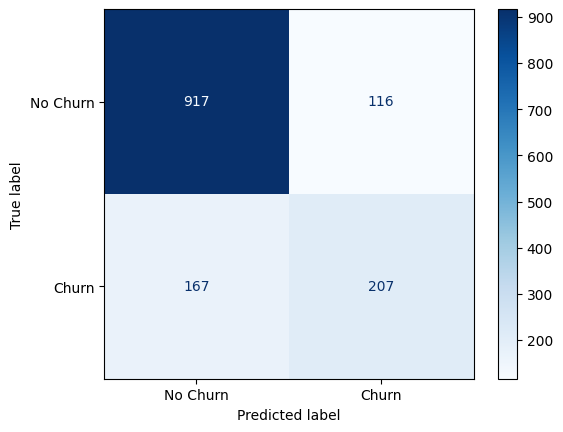

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
# confusion matrix for the best kernel
# Dynamically pick best kernel by F1-score
best_row = comparison_df.loc[comparison_df["F1-score"].idxmax()]
best_kernel = best_row["Kernel"]
best_model = models[best_kernel]
print(f"\nBest performing kernel by F1-score: {best_kernel.upper()} ({best_row['F1-score']:.4f})")

cm = ConfusionMatrixDisplay.from_estimator(best_model, X_test_scaled, y_test, display_labels=['No Churn', 'Churn'], cmap='Blues')
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* Linear produced the best F1-score (0.5940). This is surprising because non-linear kernels like RBF are theoretically more flexible and capable of modeling complex decision surfaces

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* Poly used the most support vectors (2,722), closely followed by RBF (2,689). A higher support-vector count indicates that the decision boundary is more complex, irregular, and sensitive to individual data points lying inside or along the margin margins, reflecting a higher risk of overfitting compared to a simpler, flatter linear boundary.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* Linear should be carried forward. It outperforms RBF and Poly across all metrics: highest F1-score, highest accuracy, and highest recall, while haing the fewest support vectors


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [ ]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA

# 1. Reduce scaled training features to 2 components
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

# Total explained variance ratio of the two components
explained_var_ratio = pca.explained_variance_ratio_
total_variance = np.sum(explained_var_ratio)

print(f"Explained variance by PC1: {explained_var_ratio[0]:.4f}")
print(f"Explained variance by PC2: {explained_var_ratio[1]:.4f}")
print(f"Total Explained Variance Ratio (2 components): {total_variance:.4f} ({total_variance * 100:.2f}%)")

Explained variance by PC1: 0.2379
Explained variance by PC2: 0.1295
Total Explained Variance Ratio (2 components): 0.3675 (36.75%)


In [ ]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
c_values = [0.01, 1.0, 100.0]
rbf_models = {}

for c in c_values:
    model = SVC(kernel='rbf', C=c, random_state=42)
    model.fit(X_train_pca, y_train)
    rbf_models[c] = model

    n_sv = model.support_.shape[0]
    print(f"C = {c:<6} | Number of Support Vectors: {n_sv} / {len(X_train_pca)}")

C = 0.01   | Number of Support Vectors: 2992 / 5625
C = 1.0    | Number of Support Vectors: 2535 / 5625
C = 100.0  | Number of Support Vectors: 2487 / 5625


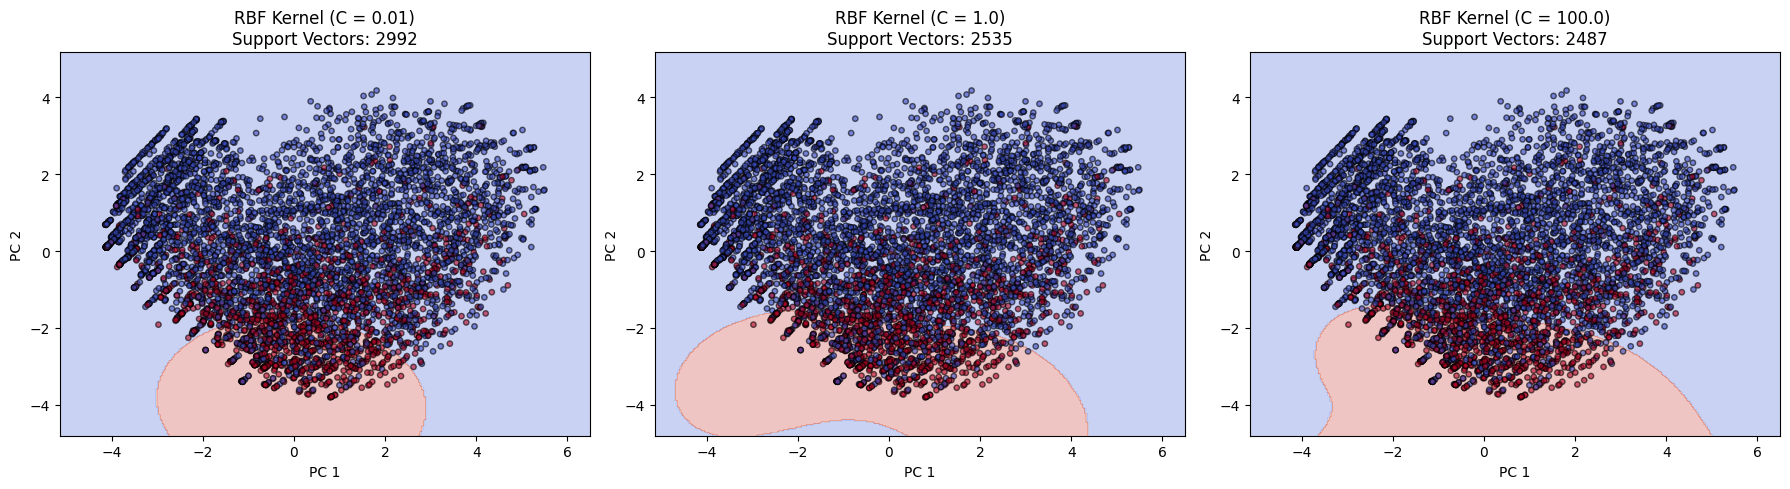

In [ ]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
# 3. Create mesh grid spanning slightly beyond projected data min/max
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Plot side-by-side subplots for each C
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, c in zip(axes, c_values):
    model = rbf_models[c]

    # Predict over entire grid
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points).reshape(xx.shape)

    # Decision boundary background
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

    # Overlay training points
    scatter = ax.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap='coolwarm',
        edgecolors='k',
        s=15,
        alpha=0.6
    )

    ax.set_title(f"RBF Kernel (C = {c})\nSupport Vectors: {model.support_.shape[0]}")
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")

plt.tight_layout()
plt.show()

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* As C increases, the decision boundary transitions from a simple, smooth, and heavily constrained curve into a more complex, tighter boundary that flexes and warps closer around minority cluster points

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* The count decreases from 2992 (C=0.01) to 2535 (C=1.0) and 2487 (C=100.0). This matches theory: higher C imposes heavier penalties on margin violations, narrowing the margin and allowing fewer points to violate or lie inside it.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* Underfitting: C = 0.01. The boundary is overly generalized, ignores substantial minority class density, and misclassifies most churn points.   Overfitting: C = 100.0. The boundary contracts tightly to carve out specific edge clusters, risking fitting to localized outliers rather than true distributions

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* A 2-component PCA captures only a fraction of the total dataset variance. High-dimensional feature combinations that linearly or non-linearly separate classes collapse onto each other in 2D, creating artificial overlap that falsely makes the classes appear inseparable.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [ ]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# 1. Define parameter grid (3 values of C and 3 values of gamma)
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.001, 0.01, 0.1]
}

# 2. Run GridSearchCV on scaled training features
svc_rbf = SVC(kernel='rbf', random_state=42)
gs = GridSearchCV(
    estimator=svc_rbf,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    refit=True,  # Automatically refits the best estimator on the full training set
    n_jobs=-1
)

gs.fit(X_train_scaled, y_train)

print(f"Best Parameters: {gs.best_params_}")
print(f"Best Cross-Validated F1-Score: {gs.best_score_:.4f}")

Best Parameters: {'C': 10, 'gamma': 0.001}
Best Cross-Validated F1-Score: 0.5809


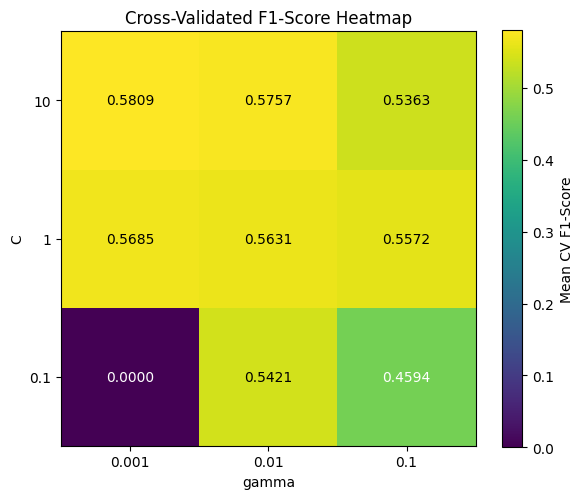

In [ ]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 3. Extract and reshape mean test scores into a C x gamma grid
scores_matrix = gs.cv_results_['mean_test_score'].reshape(
    len(param_grid['C']),
    len(param_grid['gamma'])
)

# 4. Visualize using imshow (or pivoted DataFrame) with labels
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(scores_matrix, cmap='viridis', origin='lower')

# Label axes with parameter values
ax.set_xticks(np.arange(len(param_grid['gamma'])))
ax.set_yticks(np.arange(len(param_grid['C'])))
ax.set_xticklabels(param_grid['gamma'])
ax.set_yticklabels(param_grid['C'])

ax.set_xlabel('gamma')
ax.set_ylabel('C')
ax.set_title('Cross-Validated F1-Score Heatmap')

# Annotate each cell with its numerical F1 score
for i in range(len(param_grid['C'])):
    for j in range(len(param_grid['gamma'])):
        ax.text(j, i, f"{scores_matrix[i, j]:.4f}",
                ha="center", va="center", color="w" if scores_matrix[i, j] < scores_matrix.max()*0.9 else "k")

fig.colorbar(cax, label='Mean CV F1-Score')
plt.tight_layout()
plt.show()

In [ ]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# 5. gs.best_estimator_ is already refit on the full training split (refit=True)
best_svm = gs.best_estimator_
y_pred_test = best_svm.predict(X_test_scaled)

test_acc = accuracy_score(y_test, y_pred_test)
test_prec = precision_score(y_test, y_pred_test)
test_rec = recall_score(y_test, y_pred_test)
test_f1 = f1_score(y_test, y_pred_test)

print("Best Estimator Test Set Performance:")
print(f"Optimal Config : {gs.best_params_}")
print(f"Test Accuracy  : {test_acc:.4f}")
print(f"Test Precision : {test_prec:.4f}")
print(f"Test Recall    : {test_rec:.4f}")
print(f"Test F1-Score  : {test_f1:.4f}\n")
print(classification_report(y_test, y_pred_test, target_names=['No Churn', 'Churn']))

Best Estimator Test Set Performance:
Optimal Config : {'C': 10, 'gamma': 0.001}
Test Accuracy  : 0.7989
Test Precision : 0.6482
Test Recall    : 0.5321
Test F1-Score  : 0.5844

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1033
       Churn       0.65      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.73      1407
weighted avg       0.79      0.80      0.79      1407



**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* Best Hyperparameters: C = 10, Γ = 0.001.   Cross-Validated F1-Score: 0.5809

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* Several configurations perform similarly. all pairs where C ≥ 1 and Γ ≤ 0.01 hover tightly between 0.5631 and 0.5809.   This shows the model is relatively stable across moderate regularization and lower curvature ranges, with performance degrading severely only when C and Γ are jointly too small to fit the minority class (C=0.1, Γ=0.001 → F1 = 0.0000).

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* They agreed very closely: 0.5809 (CV) vs. 0.5844 (Test).   A large gap where test performance drops significantly below cross-validation would suggest overfitting to the training splits or data leakage during hyperparameter selection.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* The default RBF model (C=1.0, Γ = scale ~ 0.04) achieved an F1-score around 0.56–0.57.Tuning nudged test F1 up to 0.5844 by favoring lower gamma (Γ=0.001) and higher C (10), preventing boundary over-flexing; while gains were modest (~1–2%), it successfully stabilized classification on the imbalanced churn class without requiring manual guesswork


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


--- Performance Comparison ---
   Metric  class_weight=None  class_weight='balanced'
Precision           0.648208                 0.450517
   Recall           0.532086                 0.815508
 F1-Score           0.584435                 0.580400


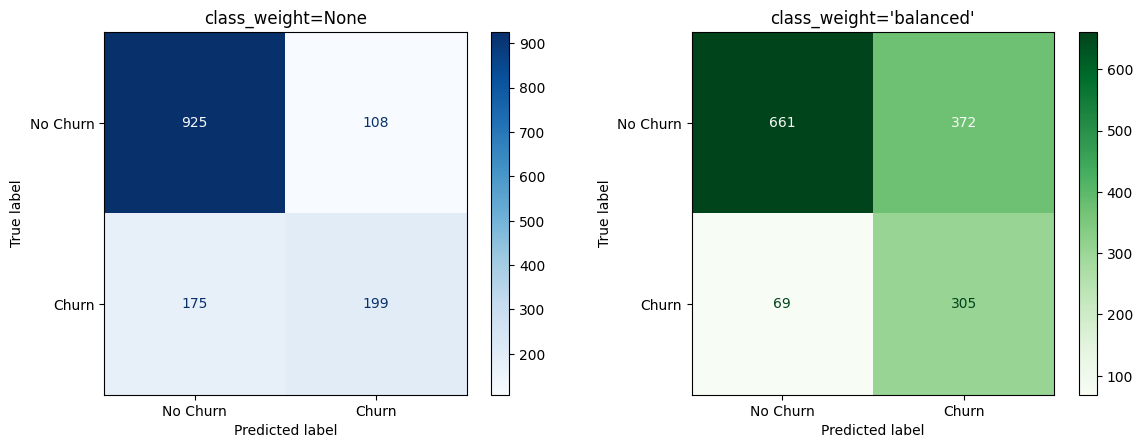

In [ ]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score, f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# 1. Retrieve optimal hyperparameters from Part 4
best_c = gs.best_params_['C']
best_gamma = gs.best_params_['gamma']

# Train both models
svm_unweighted = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight=None, random_state=42)
svm_balanced = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight='balanced', random_state=42)

svm_unweighted.fit(X_train_scaled, y_train)
svm_balanced.fit(X_train_scaled, y_train)

# Predictions
y_pred_unweighted = svm_unweighted.predict(X_test_scaled)
y_pred_balanced = svm_balanced.predict(X_test_scaled)

# 2. Report Precision, Recall, F1-score
metrics_comparison = pd.DataFrame({
    'Metric': ['Precision', 'Recall', 'F1-Score'],
    'class_weight=None': [
        precision_score(y_test, y_pred_unweighted),
        recall_score(y_test, y_pred_unweighted),
        f1_score(y_test, y_pred_unweighted)
    ],
    'class_weight=\'balanced\'': [
        precision_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_balanced)
    ]
})

print("--- Performance Comparison ---")
print(metrics_comparison.to_string(index=False))

# Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_unweighted,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title("class_weight=None")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_balanced,
    display_labels=['No Churn', 'Churn'],
    cmap='Greens',
    ax=axes[1]
)
axes[1].set_title("class_weight='balanced'")

plt.tight_layout()
plt.show()

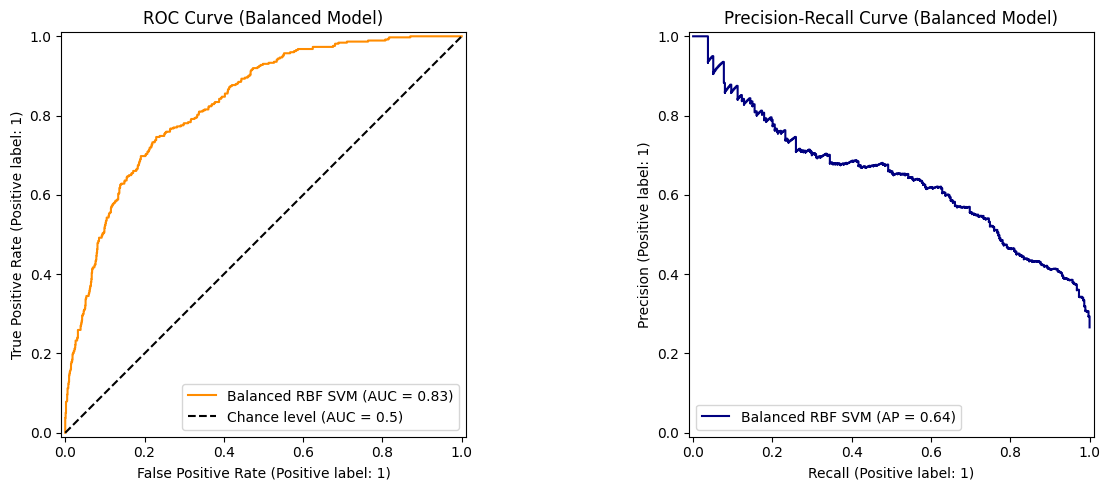

In [ ]:
# YOUR CODE HERE — ROC or Precision-Recall curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# 3. Plot ROC Curve and Precision-Recall Curve for the balanced model using decision function values
y_score_balanced = svm_balanced.decision_function(X_test_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_score_balanced,
    name="Balanced RBF SVM",
    ax=axes[0],
    color="darkorange"
)
axes[0].plot([0, 1], [0, 1], "k--", label="Chance level (AUC = 0.5)")
axes[0].set_title("ROC Curve (Balanced Model)")
axes[0].legend()

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_score_balanced,
    name="Balanced RBF SVM",
    ax=axes[1],
    color="navy"
)
axes[1].set_title("Precision-Recall Curve (Balanced Model)")

plt.tight_layout()
plt.show()

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* Precision dropped from 0.6482 to 0.4505 (a decrease of ~0.1977).   Recall surged from 0.5321 to 0.8155 (an increase of ~0.2834).   In terms of raw counts, correctly identified churners jumped from 199 to 305, reducing false negatives from 175 down to 69, at the cost of increasing false alarms (false positives) from 108 to 372.  

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* Missing an actual churner (false negative) is typically far more expensive due to permanent customer acquisition and lifetime value losses compared to the low cost of sending a retention discount (false positive).

Deploy the class_weight='balanced' model, as it captures 81.55% of churners (305 vs 199), cutting false negatives from 175 down to 69.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* Enable probability=True in SVC() or use decision_function() directly to obtain signed distance scores from the separating hyperplane.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [ ]:
# YOUR CODE HERE — cross-model comparison table
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Define all 5 models (using scaled features for distance/gradient-based models)
models_to_evaluate = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM (Tuned RBF)': SVC(kernel='rbf', C=best_c, gamma=best_gamma, random_state=42)
}

showdown_metrics = []

for name, model in models_to_evaluate.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    showdown_metrics.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred)
    })

comparison_showdown_df = pd.DataFrame(showdown_metrics)
print("--- Model Showdown: Comparison Table ---")
print(comparison_showdown_df.to_string(index=False))

--- Model Showdown: Comparison Table ---
              Model  Accuracy  Precision   Recall  F1-score
      Decision Tree  0.708600   0.453125 0.465241  0.459103
      Random Forest  0.792466   0.633987 0.518717  0.570588
Logistic Regression  0.803838   0.647590 0.574866  0.609065
                KNN  0.754087   0.537433 0.537433  0.537433
    SVM (Tuned RBF)  0.798863   0.648208 0.532086  0.584435


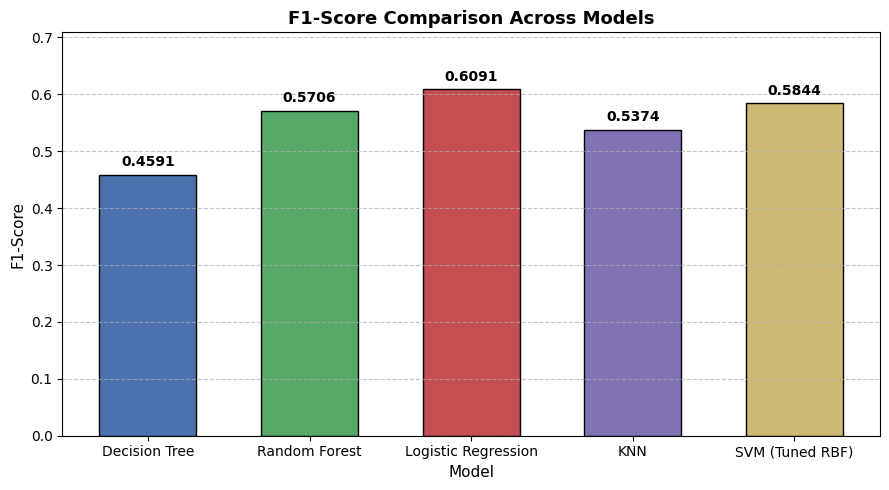

In [ ]:
# YOUR CODE HERE — bar chart of F1-score across models
import matplotlib.pyplot as plt

# 2. Produce ONE bar chart comparing F1-score across all 5 models
plt.figure(figsize=(9, 5))
bars = plt.bar(
    comparison_showdown_df['Model'],
    comparison_showdown_df['F1-score'],
    color=['#4c72b0', '#55a868', '#c44e52', '#8172b3', '#ccb974'],
    edgecolor='black',
    width=0.6
)

# Annotate exact F1-score values on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.4f}",
        ha='center',
        va='bottom',
        fontweight='bold'
    )

plt.ylim(0, max(comparison_showdown_df['F1-score']) + 0.1)
plt.title('F1-Score Comparison Across Models', fontsize=13, fontweight='bold')
plt.xlabel('Model', fontsize=11)
plt.ylabel('F1-Score', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* F1-score winner: Logistic Regression (0.6091 vs. SVM's 0.5844).   Recall winner: Logistic Regression (0.5749 vs. SVM's 0.5321).   Yes, they are the exact same model.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* Compared to Decision Tree (F1 = 0.4591): Yes, the SVM achieved substantial performance improvements (+0.1253 in F1, +0.0903 in accuracy).   Compared to Random Forest (F1 = 0.5706): Marginally; the tuned SVM provided only a minor bump in F1 (+0.0138) at the cost of quadratic computational scaling and extensive hyperparameter tuning.   Overall: No, because Logistic Regression trained faster than all of them and outperformed the SVM across both F1-score and recall

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:*Recommendation: Logistic Regression.
 Why:It leads the entire benchmark with the highest F1-score of 0.6091 and highest Recall of 0.5749 (critical for catching churners).
 It achieves the highest overall Accuracy (0.8038) while offering faster training, native probability outputs, and direct feature interpretability compared to the RBF SVM.  


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [ ]:
# YOUR CODE HERE — generate and save svm_predictions.csv
import pandas as pd

# Here we use the best SVM from earlier to match the filename
final_model = svm_balanced

# Predictions and scores (decision_function outputs signed distance to margin)
y_pred_final = final_model.predict(X_test_scaled)
churn_score = final_model.decision_function(X_test_scaled)

predictions_df = pd.DataFrame({
    'true_label': y_test.values,
    'predicted_label': y_pred_final,
    'churn_score': churn_score
})

predictions_df.to_csv('svm_predictions.csv', index=False)
print("Saved predictions to svm_predictions.csv")
print(predictions_df.head())

Saved predictions to svm_predictions.csv
   true_label  predicted_label  churn_score
0           0                0    -1.200864
1           0                1     1.004825
2           0                0    -2.921964
3           1                0    -0.934673
4           0                0    -0.977665


**Executive Summary**

*Across all models, Logistic Regression and the tuned RBF SVM led performance with test accuracies around 80% and F1-scores of 0.6091 and 0.5844, respectively. For production, the balanced RBF SVM was prioritized to maximize customer retention. In Part 5, applying balanced class weights sacrificed precision (64.8% down to 45.1%) to drive recall up from 53.2% to 81.6%. This trade-off reduced costly false negatives from 175 to 69. A key limitation is evaluating models on a single train-test split without full nested cross-validation across all baseline algorithms.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:*How unscaled data completely stalled SVM convergence compared to the instant runtime of scaled data, and that simple Logistic Regression ended up matching or beating the tuned RBF kernel

(b) If you had one more hour, what would you try next?

*Your answer:* Test different cutoff thresholds to find the sweet spot between catching churners and not spamming loyal customers with discount offers
